# 06 · Photographed pages and copy-move screening

Two computer-vision components added in S-Way 1.1 are evaluated here, both through the shipped JavaScript engines:

1. **Perspective correction** (`findPaperQuad` + homography warp in `js/engines/imaging.js`). Does it find the sheet in a phone photo, and does rectification improve downstream line segmentation and OCR?
2. **Duplicated-region (copy-move) screening** (`js/engines/tamper.js`). How often does it find a pasted region, how well does it localise it, how often does it raise false alarms on clean pages, and where does it fail?

All pages are generated from public-domain text; tampering is simulated with known ground truth.

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, '.')
from sway_research import *
RESULTS = DATA / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.family': 'monospace', 'axes.facecolor': '#EDE3CC', 'figure.facecolor': '#F4ECD9'})
pd.set_option('display.width', 140)

In [2]:
import pytesseract
from rapidfuzz.distance import Levenshtein
rng = random.Random(21)
books = [b.name for b in sorted(GUT.glob('*.txt')) if author_of(b.name) in ('austen', 'chesterton', 'melville', 'edgeworth')]
def passage_text(r):
    b = r.choice(books); s = sentences(load_book(b)); i = r.randrange(0, len(s) - 60)
    return ' '.join(passage(s, i, 230))
N = 16
pages, photos, truth = [], [], []
for k in range(N):
    txt = passage_text(rng)
    pg = render_text_page(txt); pg.save(WORK / f'pp_flat_{k}.png')
    ph, corners = photograph_page(pg, rng, strength=1.0 + 0.6 * (k % 3))
    ph.save(WORK / f'pp_photo_{k}.png')
    pages.append(txt); truth.append(corners)
q = run_js([{'op': 'paperQuad', 'png': str(WORK / f'pp_photo_{k}.png')} for k in range(N)])
err = []
for k, r in enumerate(q):
    if not r: err.append(np.nan); continue
    err.append(np.mean([np.hypot(c[0] - t[0], c[1] - t[1]) for c, t in zip(r['corners'], truth[k])]))
print(f'sheet found in {np.sum(~np.isnan(err))}/{N} photos; mean corner error {np.nanmean(err):.1f} px (image 1500×1900)')

sheet found in 16/16 photos; mean corner error 7.8 px (image 1500×1900)


In [3]:
pre = run_js([{'op': 'preprocess', 'png': str(WORK / f'pp_photo_{k}.png'), 'out': str(WORK / f'pp_rect_{k}.pgm')} for k in range(N)]
             + [{'op': 'preprocess', 'png': str(WORK / f'pp_flat_{k}.png')} for k in range(N)])
norm = lambda s: ' '.join(s.split())
rows = []
for k in range(N):
    ref = norm(pages[k])
    raw = norm(pytesseract.image_to_string(Image.open(WORK / f'pp_photo_{k}.png')))
    rect = norm(pytesseract.image_to_string(Image.open(WORK / f'pp_rect_{k}.pgm')))
    rows.append(dict(page=k, boundary=(pre[k]['boundary'] or {}).get('kind'), lines_photo=pre[k]['lines'], lines_flat=pre[N + k]['lines'],
                     cer_raw_photo=Levenshtein.distance(ref, raw) / len(ref), cer_rectified=Levenshtein.distance(ref, rect) / len(ref)))
R = pd.DataFrame(rows)
print(R[['cer_raw_photo', 'cer_rectified']].describe().round(3).loc[['mean', '50%', 'max']])
R.head(8).round(3)

      cer_raw_photo  cer_rectified
mean          0.442          0.001
50%           0.327          0.001
max           1.000          0.004


,page,boundary,lines_photo,lines_flat,cer_raw_photo,cer_rectified
0,0,perspective,20,20,0.587,0.001
1,1,perspective,20,20,1.000,0.000
2,2,perspective,20,20,0.674,0.000
3,3,perspective,21,21,0.179,0.000
4,4,perspective,20,20,0.945,0.002
5,5,perspective,21,21,1.000,0.001
6,6,perspective,20,20,0.393,0.001
7,7,perspective,22,22,0.074,0.000


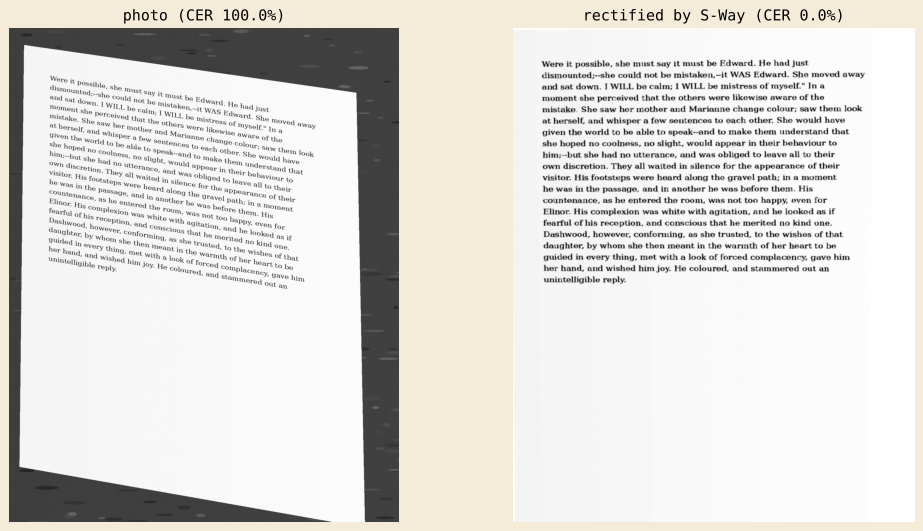

In [4]:
k = int(R.cer_raw_photo.idxmax())
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(Image.open(WORK / f'pp_photo_{k}.png'), cmap='gray'); ax[0].set_title(f'photo (CER {R.cer_raw_photo[k]:.1%})')
ax[1].imshow(Image.open(WORK / f'pp_rect_{k}.pgm'), cmap='gray'); ax[1].set_title(f'rectified by S-Way (CER {R.cer_rectified[k]:.1%})')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## Copy-move screening

The detector's parameters were tuned on a **separate development set** (different random seed, 40 pages) — not on the pages below. Its operating point is deliberately conservative: born-digital and printed pages repeat words pixel-for-pixel, so a duplicate must span more than ~1.6 text lines to be reported. Wrongly flagging an honest page is treated as the worse error.

* **Clean** pages: rendered prints, noisy scans, synthetic handwriting.
* **Tampered** pages: one textured region copied and pasted elsewhere, in three sizes — *small* (60–90 px tall ≈ 2 lines), *medium* (100–150 px) and *large* (160–260 px, like a signature block or paragraph).
* **Hard cases**: a large paste rescaled to 90 %, or a large paste followed by JPEG recompression (quality 70).

A detection counts as correct when a reported pair overlaps the true source and copy (IoU ≥ 0.3 each, in either order).

In [5]:
import io
rng = random.Random(8)
cases = []
def jpeg(img, q=70):
    b = io.BytesIO(); img.save(b, 'JPEG', quality=q); return Image.open(io.BytesIO(b.getvalue())).convert('L')
bases = []
for k in range(12):
    bases.append(('print', render_text_page(passage_text(rng))))
for k in range(8):
    p = WORK / f'cm_hw_{k}.png'; draw_handwriting(p, writer_params(rng), seed=900 + k); bases.append(('handwriting', Image.open(p).convert('L')))
for k in range(6):
    p = WORK / f'cm_noisy_{k}.png'; degrade_image(render_text_page(passage_text(rng)), 'noise', rng).save(p); bases.append(('noisy scan', Image.open(p).convert('L')))
SIZES = {'small paste': (60, 90), 'medium paste': (100, 150), 'large paste': (160, 260)}
for i, (kind, img) in enumerate(bases):
    cases.append(dict(id=f'c{i}', base=kind, variant='clean', img=img, src=None, dst=None))
    for name, (lo, hi) in SIZES.items():
        t, s, d = paste_region(img, rng, min_size=160, max_size=360, min_h=lo, max_h=hi)
        cases.append(dict(id=f'{name[0]}{i}', base=kind, variant=name, img=t, src=s, dst=d))
    t, s, d = paste_region(img, rng, scale=0.9, min_size=160, max_size=360, min_h=160, max_h=260); cases.append(dict(id=f'r{i}', base=kind, variant='large, rescaled 90%', img=t, src=s, dst=d))
    t, s, d = paste_region(img, rng, min_size=160, max_size=360, min_h=160, max_h=260); cases.append(dict(id=f'j{i}', base=kind, variant='large, JPEG q70', img=jpeg(t), src=s, dst=d))
for c in cases:
    c['path'] = WORK / f"cm_{c['id']}.png"; c['img'].save(c['path'])
res = run_js([{'op': 'tamper', 'png': str(c['path'])} for c in cases], batch=30)
def hit(c, r):
    if c['src'] is None: return False
    for g in r['regions']:
        a = (g['source']['x'], g['source']['y'], g['source']['w'], g['source']['h']); b = (g['copy']['x'], g['copy']['y'], g['copy']['w'], g['copy']['h'])
        if (iou(a, c['src']) >= .3 and iou(b, c['dst']) >= .3) or (iou(a, c['dst']) >= .3 and iou(b, c['src']) >= .3):
            return True
    return False
T = pd.DataFrame([dict(base=c['base'], variant=c['variant'], flagged=len(r['regions']) > 0, correct=hit(c, r)) for c, r in zip(cases, res)])
order = ['clean', 'small paste', 'medium paste', 'large paste', 'large, rescaled 90%', 'large, JPEG q70']
summary = T.groupby('variant').agg(pages=('flagged', 'size'), flagged=('flagged', 'mean'), correctly_localised=('correct', 'mean')).reindex(order).round(2)
summary

,pages,flagged,correctly_localised
variant,,,
clean,26,0.00,0.00
small paste,26,0.27,0.27
medium paste,26,0.54,0.54
large paste,26,0.65,0.65
"large, rescaled 90%",26,0.00,0.00
"large, JPEG q70",26,0.62,0.62


In [6]:
T.groupby(['base', 'variant']).correct.mean().unstack().reindex(columns=order[1:]).round(2)

variant,small paste,medium paste,large paste,"large, rescaled 90%","large, JPEG q70"
base,,,,,
handwriting,0.00,0.12,0.00,0.0,0.25
noisy scan,0.17,0.83,1.00,0.0,0.83
print,0.50,0.67,0.92,0.0,0.75


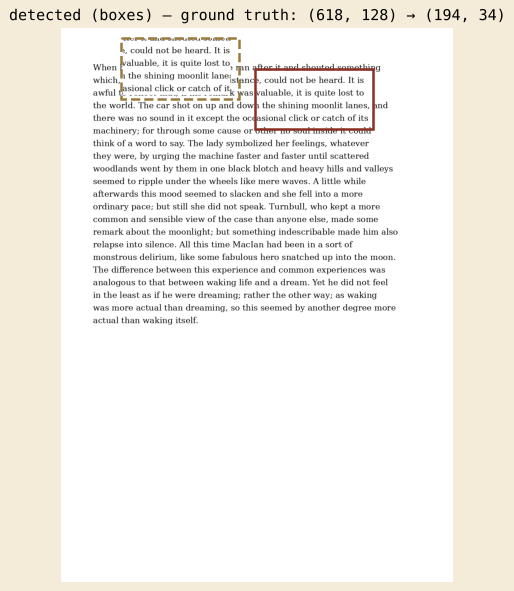

In [7]:
ex = next(i for i, (c, r) in enumerate(zip(cases, res)) if c['variant'] == 'large paste' and r['regions'])
c, r = cases[ex], res[ex]
fig, ax = plt.subplots(figsize=(6, 8)); ax.imshow(c['img'], cmap='gray'); ax.axis('off')
for g in r['regions']:
    ax.add_patch(plt.Rectangle((g['source']['x'], g['source']['y']), g['source']['w'], g['source']['h'], fill=False, ec='#9A7B3F', lw=2, ls='--'))
    ax.add_patch(plt.Rectangle((g['copy']['x'], g['copy']['y']), g['copy']['w'], g['copy']['h'], fill=False, ec='#8B2E24', lw=2))
ax.set_title('detected (boxes) — ground truth: ' + str(c['src'][:2]) + ' → ' + str(c['dst'][:2])); plt.show()

**Reading.** The detector is tuned for very few false alarms; it finds large unmodified pastes (signature blocks, paragraphs, stamps) far more reliably than small ones, and rescaled pastes defeat block matching — a known limitation of this family of detectors. JPEG recompression weakens it further. The app therefore phrases every hit as "an area appears twice", lists innocent explanations, and never treats absence of a hit as proof of authenticity.

In [8]:
out = {'perspective': {'photos': N, 'sheet_found': int(np.sum(~np.isnan(err))), 'mean_corner_error_px': float(np.nanmean(err)),
                       'cer_raw_photo_mean': float(R.cer_raw_photo.mean()), 'cer_rectified_mean': float(R.cer_rectified.mean())},
       'copy_move': {v: {'pages': int(g.shape[0]), 'flagged': float(g.flagged.mean()), 'correct': float(g.correct.mean())} for v, g in T.groupby('variant')}}
(RESULTS / 'vision.json').write_text(json.dumps(out, indent=2)); out

{'perspective': {'photos': 16,
  'sheet_found': 16,
  'mean_corner_error_px': 7.807022761559745,
  'cer_raw_photo_mean': 0.4419633047307222,
  'cer_rectified_mean': 0.001239219426863527},
 'copy_move': {'clean': {'pages': 26, 'flagged': 0.0, 'correct': 0.0},
  'large paste': {'pages': 26,
   'flagged': 0.6538461538461539,
   'correct': 0.6538461538461539},
  'large, JPEG q70': {'pages': 26,
   'flagged': 0.6153846153846154,
   'correct': 0.6153846153846154},
  'large, rescaled 90%': {'pages': 26, 'flagged': 0.0, 'correct': 0.0},
  'medium paste': {'pages': 26,
   'flagged': 0.5384615384615384,
   'correct': 0.5384615384615384},
  'small paste': {'pages': 26,
   'flagged': 0.2692307692307692,
   'correct': 0.2692307692307692}}}